<a href="https://colab.research.google.com/github/Taheri1400/deep-learning-projects/blob/main/Simple_RNN_keras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 dir=rtl align=center style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
پیاده‌سازی شبکه‌های عصبی بازگشتی در کراس
</font>
</h1>


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
هدف مدل در این مسئله دریافت یک رشته به فرم "123+456" است و هدف مسئله به‌دست آوردن مقدار منطقی این معادله به صورت یک رشته می‌باشد. دقت کنید ورودی‌ها و خروجی مسئله رشته هستند و با آن‌ها مانند اعداد برخورد نمی‌شود.
</font>
</p>

<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
وارد کردن کتابخانه‌های مورد نیاز</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
برای شروع پیاده‌سازی شبکه‌های عصبی بازگشتی، مانند تمامی پیاده‌سازی‌های دیگر ابتدا بخش `import` را اضافه می کنیم و کتابخانه‌های مورد نیاز را وارد می‌کنیم.
</font>
</p>

In [1]:
from __future__ import print_function
from tensorflow import keras
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
class colors:
    ok = '\033[92m'
    fail = '\033[91m'
    close = '\033[0m'

<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
    بارگیری و بررسی و پیش‌پردازش داده‌ها
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
پس از وارد کردن کتابخانه‌ها دو فایل نامپای را می‌خوانیم که فایل `questions.npy` رشته‌های ورودی و فایل  `expected.npy` برچسب آن‌ها هستند. از این فایل به عنوان داده‌های ورودی استفاده می‌شود. </font>
</p>

In [3]:
questions = np.load('./questions.npy')
expected = np.load('./expected.npy')

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
پس از بارگیری داده‌ها ابتدا نگاهی سطحی به آن‌ها می‌اندازیم، هرچند در این مسئله می‌دانیم اعداد نهایت سه رقمی هستند بنابراین رشته‌های ورودی نهایت ۷ کاراکتر خواهند داشت (سه کاراکتر برای عدد اول، سه کاراکتر برای عدد دوم و یک کاراکتر جمع `+`) و با جمع آن‌ها نهایت یک عدد چهار رقمی خواهیم داشت که نیاز به چهار کاراکتر دارد.
 </font>
</p>

In [7]:
questions

array(['3+5    ', '78+56  ', '90+226 ', ..., '539+326', '332+27 ',
       '269+504'], dtype='<U7')

In [4]:
print(questions)
print(expected)
DIGITS = 3
chars = '0123456789+ '

['3+5    ' '78+56  ' '90+226 ' ... '539+326' '332+27 ' '269+504']
['8   ' '134 ' '316 ' ... '865 ' '359 ' '773 ']


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
تابع زیر عملیات رمزگذاری رشته‌ها به زبان مدل را انجام می‌دهد.
</font>
</p>

In [8]:
def encode(C, chars):
        char_indices = dict((c, i) for i, c in enumerate(chars))
        x = np.zeros((len(C), len(chars)))
        for i, c in enumerate(C):
            x[i, char_indices[c]] = 1
        return x

In [10]:
x = encode('524+317', chars)
print(x)
print(x.shape)

[[0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]]
(7, 12)


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
تابع زیر رشته‌های رمزگذاری شده به زبان مدل را به رشته‌های قابل فهم برای انسان تبدیل می‌کند، به عبارت دیگر این تابع عملیات رمزگشایی را انجام می‌دهد.
 </font>

</p>

In [9]:
def decode(x, chars, calc_argmax = True):
    indices_char = dict((i, c) for i, c in enumerate(chars))
    if calc_argmax:
        x = x.argmax(axis=-1)
    return ''.join(indices_char[x] for x in x)

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
دو مثال از نحوه کار کرد توابع رمزگذار و رمزگشا را در قطعه کد زیر مشاهده می‌کنیم
 </font>

</p>

In [11]:
x_sample = questions[-1]
encoded = encode(x_sample, chars)
print(f'{x_sample}\n encoded :\n {encoded}')

269+504
 encoded :
 [[0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]]


In [12]:
y_sample = expected[-1]
encoded = encode(y_sample, chars)
print(f'{y_sample}\n encoded :\n {encoded}')

773 
 encoded :
 [[0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]]


In [18]:
ques = ['524+317', '123+456', '321+111']

print(list(enumerate(ques)))

[(0, '524+317'), (1, '123+456'), (2, '321+111')]


<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
تابع زیر عملیات رمزگذاری را برای تمامی مجموعه‌داده انجام می‌دهد.
 </font>

</p>

In [20]:
def vectorization(questions, expected ,DIGITS = DIGITS, chars = chars):
    MAXLEN = DIGITS + 1 + DIGITS
    x = np.zeros((len(questions), MAXLEN, len(chars)))
    y = np.zeros((len(questions), DIGITS + 1, len(chars)))
    for i, sentence in enumerate(questions):
        x[i] = encode(sentence, chars)
    for i, sentence in enumerate(expected):
        y[i] = encode(sentence, chars)
    return x, y

In [21]:
X, y = vectorization(questions, expected)
x_train, x_val, y_train, y_val = train_test_split(X, y, test_size=0.1, random_state=42)
print(f'Training Data: X- {x_train.shape} Y- {y_train.shape}')
print(f'Validation Data: X- {x_val.shape} Y- {y_val.shape}')

Training Data: X- (45000, 7, 12) Y- (45000, 4, 12)
Validation Data: X- (5000, 7, 12) Y- (5000, 4, 12)


<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
ساخت مدل
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
تا اینجا به پیش‌پرداز مدل پرداختیم حال قصد داریم به ساخت مدلی که مسئله را برای ما حل کند بپردازیم. برای ساخت این مدل پس از تعریف لایه‌ی ورودی از یک لایه‌ی بازگشتی با تعداد ۱۲۸ نورون برای ساخت بخش اول شبکه، استفاده می‌کنیم، سپس با استفاده خروجی این لایه را با استفاده از لایه کپی کرده و به لایه‌ی بازگشتی بعدی با ۲۵۶ نورون و خروجی دنباله‌ای می‌دهیم. در نهایت با استفاده از یک لایه‌ی متراکم خروجی نهایی را مشخص می‌کنیم.
    
</p>

In [22]:
HIDDEN_SIZE = 128
BATCH_SIZE = 64

In [23]:
model = keras.models.Sequential()
model.add(keras.layers.Input(shape=(DIGITS*2 + 1, len(chars))))
model.add(keras.layers.SimpleRNN(HIDDEN_SIZE))
model.add(keras.layers.RepeatVector(DIGITS + 1))
model.add(keras.layers.SimpleRNN(HIDDEN_SIZE*2, return_sequences=True))
model.add(keras.layers.Dense(len(chars), activation='softmax'))
model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

In [24]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        18,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 4, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 4, 256)         │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4, 12)          │         3,084 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 119,692 (467.55 KB)

 Trainable params: 119,692 (467.55 KB)

 Non-trainable params: 0 (0.00 B)

<h2 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
آموزش مدل
</font>
</h2>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
در این قسمت پس از ساخت مدل به آموزش و بررسی روند آموزش می‌پردازیم.
</p>

In [25]:
train_acc = []
valid_acc = []
Iterations = 15
epochs = 5

for iteration in range(1, Iterations+1):
    print('-' * 50)
    print('Iteration', iteration)
    history = model.fit(x_train, y_train,
                        batch_size=BATCH_SIZE,
                        epochs=epochs,
                        validation_data=(x_val, y_val))

    train_acc.append(history.history['accuracy'])
    valid_acc.append(history.history['val_accuracy'])

    for i in range(10):
        ind = np.random.randint(0, len(x_val))
        rowx, rowy = x_val[np.array([ind])], y_val[np.array([ind])]
        q = decode(rowx[0], chars)
        correct = decode(rowy[0], chars)
        pred = model.predict(rowx)
        guess = decode(pred.argmax(-1)[0], chars ,calc_argmax=False)
        print('Q', q, end=' ')
        print('T', correct, end=' ')
        if correct == guess:
            print(colors.ok + '☑' + colors.close, end=' ')
        else:
            print(colors.fail + '☒' + colors.close, end=' ')
        print(guess)


--------------------------------------------------
Iteration 1
Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.4167 - loss: 1.5964 - val_accuracy: 0.4811 - val_loss: 1.3859
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.5626 - loss: 1.1477 - val_accuracy: 0.6409 - val_loss: 0.9322
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.7093 - loss: 0.7526 - val_accuracy: 0.7389 - val_loss: 0.6669
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.7902 - loss: 0.5566 - val_accuracy: 0.8026 - val_loss: 0.5144
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.8410 - loss: 0.4390 - val_accuracy: 0.8529 - val_loss: 0.4119
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 272ms/step
Q 784+303 T 1087 ☑ 1087
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Q 78+549  T 627  ☑ 627 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Q 1+259   T 260  ☒ 250 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Q 7+167   T 174  ☑ 174 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
Q 96+

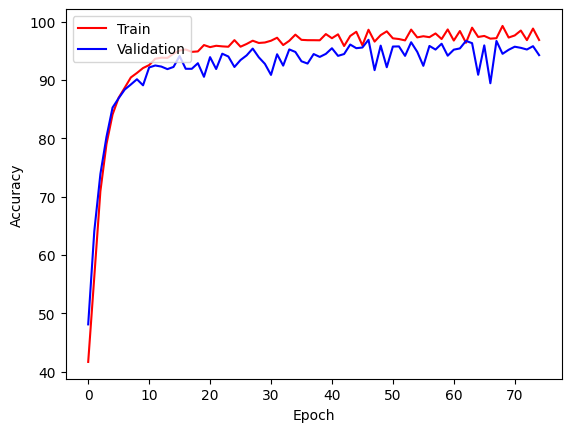

In [26]:
plt.plot( (np.array(train_acc)*100).flatten(), 'r')
plt.plot( (np.array(valid_acc)*100).flatten(), 'b')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()